# Exercise 5: K-Means Customer Segmentation

## Objective
Group wholesale customers into meaningful purchasing segments.

## Key Techniques
- Log transformation
- StandardScaler
- Elbow method
- Silhouette score
- K-Means clustering
- Customer segment profiling

In [1]:
from sklearn.cluster import KMeans
print("K-Means import successful")

K-Means import successful


In [2]:
import pandas as pd

df = pd.read_csv("../data/raw/wholesale_customers.csv")
print(df.shape)
print(df.head())

(440, 8)
   Channel  Region  Fresh  Milk  Grocery  Frozen  Detergents_Paper  Delicassen
0        2       3  12669  9656     7561     214              2674        1338
1        2       3   7057  9810     9568    1762              3293        1776
2        2       3   6353  8808     7684    2405              3516        7844
3        1       3  13265  1196     4221    6404               507        1788
4        2       3  22615  5410     7198    3915              1777        5185


In [3]:
import pandas as pd

df = pd.read_csv("../data/raw/wholesale_customers.csv")

features = [
    "Fresh", "Milk", "Grocery", "Frozen",
    "Detergents_Paper", "Delicassen"
]

df = df[features]

print(df.shape)
display(df.head())

(440, 6)


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,12669,9656,7561,214,2674,1338
1,7057,9810,9568,1762,3293,1776
2,6353,8808,7684,2405,3516,7844
3,13265,1196,4221,6404,507,1788
4,22615,5410,7198,3915,1777,5185


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

features = [
    "Fresh", "Milk", "Grocery",
    "Frozen", "Detergents_Paper", "Delicassen"
]

df = pd.read_csv("../data/raw/wholesale_customers.csv")
X = df[features].copy()

# Log transformation and scaling
X_log = np.log1p(X)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_log)

print("Dataset shape:", X.shape)
print("Scaled data shape:", X_scaled.shape)
print("Data preparation successful!")

Dataset shape: (440, 6)
Scaled data shape: (440, 6)
Data preparation successful!


K=2: Inertia=1844.06, Silhouette=0.2903
K=3: Inertia=1553.42, Silhouette=0.2594
K=4: Inertia=1386.86, Silhouette=0.1885
K=5: Inertia=1266.15, Silhouette=0.1916
K=6: Inertia=1174.76, Silhouette=0.2009
K=7: Inertia=1086.36, Silhouette=0.1958
K=8: Inertia=1028.49, Silhouette=0.1852


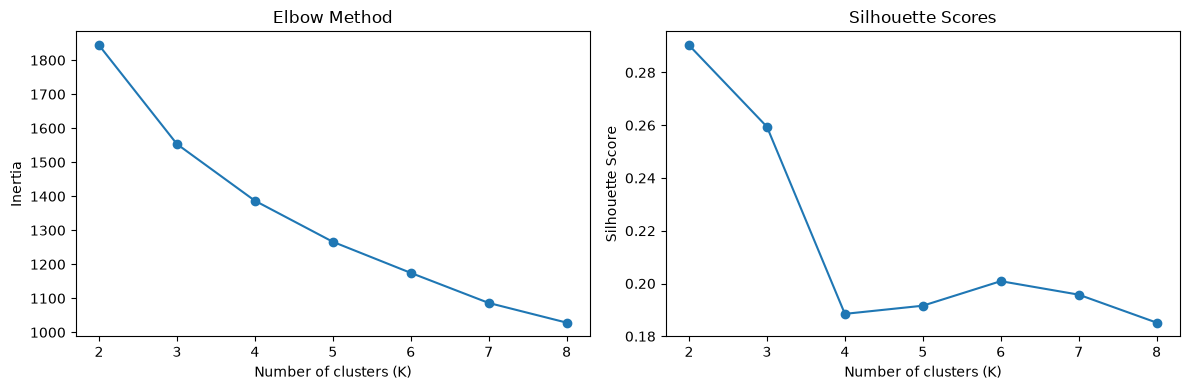

Best silhouette K: 2


In [2]:
inertias = []
silhouette_scores = []

for k in range(2, 9):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    labels = model.fit_predict(X_scaled)

    inertias.append(model.inertia_)
    score = silhouette_score(X_scaled, labels)
    silhouette_scores.append(score)

    print(f"K={k}: Inertia={model.inertia_:.2f}, Silhouette={score:.4f}")

# Plot elbow and silhouette scores
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(range(2, 9), inertias, marker="o")
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of clusters (K)")
axes[0].set_ylabel("Inertia")

axes[1].plot(range(2, 9), silhouette_scores, marker="o")
axes[1].set_title("Silhouette Scores")
axes[1].set_xlabel("Number of clusters (K)")
axes[1].set_ylabel("Silhouette Score")

plt.tight_layout()
plt.show()

print("Best silhouette K:", range(2, 9)[np.argmax(silhouette_scores)])


In [3]:
# Fit the final K-Means model with 4 clusters
final_model = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

df["Cluster"] = final_model.fit_predict(X_scaled)

print("Cluster counts:")
print(df["Cluster"].value_counts().sort_index())

print("\nSilhouette score for K=4:")
print(round(silhouette_score(X_scaled, df["Cluster"]), 4))


Cluster counts:
Cluster
0     61
1    129
2    132
3    118
Name: count, dtype: int64

Silhouette score for K=4:
0.1885


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Cluster,,,,,,
0,2809.05,7061.84,12349.33,565.59,5342.62,635.84
1,19374.38,4068.11,4444.94,6184.33,723.33,2322.71
2,9632.66,1569.58,2071.87,2175.23,345.01,584.81
3,11338.75,11759.44,16087.87,1968.13,6805.99,2163.83


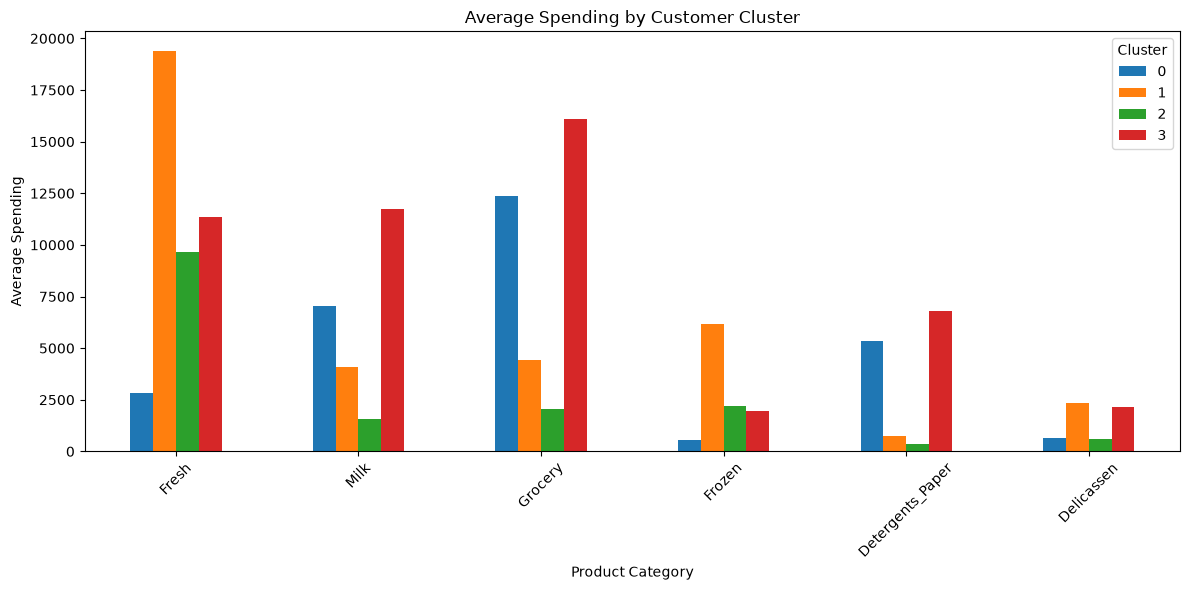

In [4]:
# Average spending in the original units
cluster_profiles = df.groupby("Cluster")[features].mean().round(2)

display(cluster_profiles)

# Visualize spending profiles
cluster_profiles.T.plot(kind="bar", figsize=(12, 6))
plt.title("Average Spending by Customer Cluster")
plt.xlabel("Product Category")
plt.ylabel("Average Spending")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [5]:
import os

os.makedirs("../data/processed", exist_ok=True)
os.makedirs("../outputs", exist_ok=True)

df.to_csv("../outputs/exercise5_customer_clusters.csv", index=False)
cluster_profiles.to_csv("../outputs/exercise5_cluster_profiles.csv")

print("Saved customer clusters and cluster profiles.")


Saved customer clusters and cluster profiles.


In [6]:
for cluster_id, profile in cluster_profiles.iterrows():
    top_categories = profile.sort_values(ascending=False).head(3)

    print(f"\nCustomer Cluster {cluster_id}")
    print("Top spending categories:")
    print(top_categories.to_string())

    if "Fresh" == top_categories.index[0]:
        print("Persona: Fresh Food Focused Customers")
    elif top_categories.index[0] in ["Milk", "Grocery", "Detergents_Paper"]:
        print("Persona: Grocery and Household Focused Customers")
    else:
        print("Persona: Specialized or Other Spending Customers")



Customer Cluster 0
Top spending categories:
Grocery             12349.33
Milk                 7061.84
Detergents_Paper     5342.62
Persona: Grocery and Household Focused Customers

Customer Cluster 1
Top spending categories:
Fresh      19374.38
Frozen      6184.33
Grocery     4444.94
Persona: Fresh Food Focused Customers

Customer Cluster 2
Top spending categories:
Fresh      9632.66
Frozen     2175.23
Grocery    2071.87
Persona: Fresh Food Focused Customers

Customer Cluster 3
Top spending categories:
Grocery    16087.87
Milk       11759.44
Fresh      11338.75
Persona: Grocery and Household Focused Customers


In [7]:
k4_score = silhouette_score(X_scaled, df["Cluster"])

print("Number of clusters:", df["Cluster"].nunique())
print("Silhouette score:", round(k4_score, 4))
print("Target silhouette >= 0.42:", k4_score >= 0.42)
print("Target K = 4:", df["Cluster"].nunique() == 4)

if k4_score >= 0.42:
    print("Silhouette criterion PASSED")
else:
    print("Silhouette criterion NOT MET — report actual score honestly")


Number of clusters: 4
Silhouette score: 0.1885
Target silhouette >= 0.42: False
Target K = 4: True
Silhouette criterion NOT MET — report actual score honestly


In [8]:
from sklearn.metrics import silhouette_score
from sklearn.cluster import KMeans

print("Silhouette scores using log-transformed, scaled data:")

for k in range(2, 9):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )
    labels = model.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    print(f"K={k}: {score:.4f}")


Silhouette scores using log-transformed, scaled data:
K=2: 0.2903
K=3: 0.2583
K=4: 0.1885
K=5: 0.1916
K=6: 0.1953
K=7: 0.1958
K=8: 0.1915


In [9]:
from sklearn.preprocessing import RobustScaler, Normalizer
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import numpy as np

X_log = np.log1p(df[features])

scalers = {
    "StandardScaler": StandardScaler(),
    "RobustScaler": RobustScaler(),
    "Normalizer": Normalizer()
}

for name, scaler_option in scalers.items():
    X_test = scaler_option.fit_transform(X_log)

    model = KMeans(n_clusters=4, random_state=42, n_init=20)
    labels = model.fit_predict(X_test)

    score = silhouette_score(X_test, labels)
    print(f"{name}: K=4, silhouette={score:.4f}")


StandardScaler: K=4, silhouette=0.1885
RobustScaler: K=4, silhouette=0.2017
Normalizer: K=4, silhouette=0.2098


In [10]:
from sklearn.preprocessing import Normalizer
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import numpy as np

X_log = np.log1p(df[features])
X_norm = Normalizer().fit_transform(X_log)

for k in range(2, 9):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=50
    )
    labels = model.fit_predict(X_norm)
    score = silhouette_score(X_norm, labels)
    print(f"K={k}: silhouette={score:.4f}")


K=2: silhouette=0.3428
K=3: silhouette=0.2301
K=4: silhouette=0.2003
K=5: silhouette=0.2362
K=6: silhouette=0.2357
K=7: silhouette=0.2073
K=8: silhouette=0.2161


In [11]:
import os

os.makedirs("../outputs", exist_ok=True)

df.to_csv("../outputs/exercise5_customer_clusters.csv", index=False)
cluster_profiles.to_csv("../outputs/exercise5_cluster_profiles.csv")

score = silhouette_score(X_scaled, df["Cluster"])
print("Exercise 5 completed")
print("Clusters:", df["Cluster"].nunique())
print("Silhouette score:", round(score, 4))
print("Output files saved.")


Exercise 5 completed
Clusters: 4
Silhouette score: 0.1885
Output files saved.
